# 002d — Impact of the ASC flatfile filter bug on the IM correlations

nb 002 builds the active shallow crust (ASC) flatfile from every ESM record that is **not** in
the ESHM20 subduction in-slab (`sslab`), subduction interface (`sinter`) or Vrancea (`vran`)
datasets. The first filter in `manage_flatfiles.get_active_shallow_crust_flatfile` was meant to
remove the records of those three datasets, but removed nothing: it called
`database_df.index.isin(deep_events)` with a DataFrame, and `isin` then compares the row labels
with the frame's **column names**, which never match. The function now removes the regional
records by matching the four ESM record keys (`event_id, network_code, station_code,
sensor_depth_m`).

This notebook compares the nb 002 outputs from before the fix (frozen in
`data_processed/02_im_correlation_model/baseline_for_bug_check/`) with the live outputs from the
fixed code. It answers one question: **do the ASC correlations change by an amount that
matters?** The criterion, set before the comparison was run, is

> the change is immaterial if every |Δρ| is well below one sampling standard error.

The task is described in `dump/tasks_and_plans/task_20261111_asc_flatfile_filter_bug_check.md`.
The helper scripts used here (`compare_002_outputs.py`, `count_leakage.py`,
`check_rake_issue.py`) are in `dump/bug_check/`.

Figures are saved to `results/02_im_correlation_model/bug_check/`.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from phd_project.config.config import load_config
from phd_project.scripts.WP1_ground_motion_set.correlation import read_correlation_csv

cfg = load_config()
PROCESSED_DATA = Path(cfg["proc_data"]["corr_model"])
RESULTS = Path(cfg["results"]["corr_model"])

# the frozen pre-fix outputs, and the folder for this notebook's figures
BASELINE = PROCESSED_DATA / "baseline_for_bug_check"
FIG_DIR = RESULTS / "bug_check"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The comparison helpers live in dump/bug_check/ (they are also run as standalone scripts).
# The repository root is the first parent folder holding pyproject.toml.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(REPO / "dump" / "bug_check"))
import compare_002_outputs as cmp   # noqa: E402
import count_leakage as leak         # noqa: E402
import check_rake_issue as rake      # noqa: E402

# the live (fixed) outputs: (data_processed, results) folders
FIXED_PROC, FIXED_RES = cmp.resolve_root("live")
BASE_PROC, BASE_RES = cmp.resolve_root(BASELINE)

FAULT_TYPES = ["normal", "reverse", "strikeslip"]
RHO_TAGS = ["rho_total", "rho_total_B", "rho_dBe", "rho_dS2Ss", "rho_dWSes"]
TRT_COLOURS = {"sslab": "tab:red", "sinter": "tab:blue", "vran": "tab:green"}

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def savefig(fig, name: str) -> None:
    # every saved figure has an opaque white background
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight", facecolor="w")

## 1. What leaked

Which regional records were in the pre-fix ASC flatfile? A record leaked if its four record
keys appear in one of the three ESHM20 ID lists (`data_raw/eshm20_trt_record_ids/`). A record
named in more than one list is shown as an overlap and counted once in the *any* row.

The second table shows how many records survive each stage of the ASC filter, in total and per
regional list. With stage (i) removing nothing, it shows which filter was keeping regional
records out: the 40 km depth cut (ii), the "at least 3 records per event" rule (iii), or the
missing-data drops of nb 002 cell 15.

The tables are computed from the *baseline* ASC flatfiles. They are the same for all three
fault types (checked below), so only `reverse` is shown.

In [2]:
leak_res = leak.compute(BASELINE)

# the leakage does not depend on the fault type: check, then show one
for ft in FAULT_TYPES:
    pd.testing.assert_frame_equal(leak_res[ft]["per_trt"], leak_res["reverse"]["per_trt"])
    pd.testing.assert_frame_equal(leak_res[ft]["stages"], leak_res["reverse"]["stages"])
print("Leakage tables are identical for the three fault types.\n")

per_trt = leak_res["reverse"]["per_trt"]
stages = leak_res["reverse"]["stages"]
print("Leaked records per regional list (share = % of the baseline ASC totals):")
display(per_trt.round(2))
print("Records surviving each stage of the ASC filter:")
display(stages)

Leakage tables are identical for the three fault types.

Leaked records per regional list (share = % of the baseline ASC totals):


,records,records_share_%,events,events_share_%,stations,stations_share_%
sslab,24.0,0.13,4.0,0.38,21.0,1.12
sinter,382.0,2.07,63.0,6.06,123.0,6.58
vran,0.0,0.00,0.0,0.00,0.0,0.00
overlap (in >1 list),0.0,0.00,0.0,0.00,0.0,0.00
any regional list,406.0,2.20,67.0,6.45,126.0,6.74
ASC total,18481.0,100.00,1039.0,100.00,1869.0,100.00


Records surviving each stage of the ASC filter:


,all records,regional records (any list),sslab,sinter,vran,overlap (in >1 list),regional events
ESM flatfile,23014,2323,704,681,938,0,349
(i) regional-record filter (no-op),23014,2323,704,681,938,0,349
(ii) hypocentral depth <= 40 km,20947,576,29,547,0,0,127
(iii) >= 3 records per event,19941,503,26,477,0,0,74
missing-data drops (cell 15) = saved ASC flatfile,18481,406,24,382,0,0,67


### Where the leaked records sit in the data

Magnitude against rupture distance, hypocentral depth and station locations of the baseline
ASC records, with the leaked records coloured by regional list. If the leaked records cluster
in one corner (deep events, a few stations), the change of the fix will be concentrated in the
IMs and residual components that are sensitive to that corner.

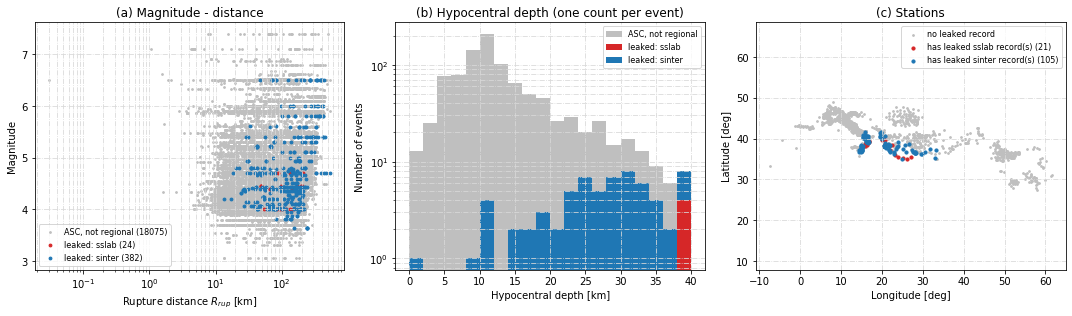

In [3]:
asc_base = leak.read_asc_flatfile(BASE_PROC / "reverse" / "flatfiles" / "asc_reverse_flatfile.csv")
labels = leak_res["reverse"]["labels"].reindex(asc_base.index)
leaked = labels != ""

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))

# (a) magnitude - distance
ax = axs[0]
ax.scatter(asc_base.loc[~leaked, "rrup"], asc_base.loc[~leaked, "mag"], s=3, c="0.75",
           label=f"ASC, not regional ({(~leaked).sum()})")
for tag, col in TRT_COLOURS.items():
    m = labels == tag
    if m.any():
        ax.scatter(asc_base.loc[m, "rrup"], asc_base.loc[m, "mag"], s=8, c=col,
                   label=f"leaked: {tag} ({m.sum()})")
ax.set_xscale("log")
ax.set_xlabel("Rupture distance $R_{rup}$ [km]")
ax.set_ylabel("Magnitude")
ax.set_title("(a) Magnitude - distance")
ax.grid(True, which="both", ls="-.", color="0.85")
ax.legend(fontsize=8)

# (b) hypocentral depth; one depth per event so large events do not dominate
ax = axs[1]
ev = asc_base.assign(trt=labels).groupby("event_id").agg(depth=("hypo_depth", "first"),
                                                          trt=("trt", "max"))
bins = np.arange(0, 42, 2)
ax.hist(ev.loc[ev["trt"] == "", "depth"], bins=bins, color="0.75", label="ASC, not regional")
bottom = np.zeros(len(bins) - 1)
for tag, col in TRT_COLOURS.items():
    d = ev.loc[ev["trt"] == tag, "depth"]
    if len(d):
        h, _ = np.histogram(d, bins=bins)
        ax.bar(bins[:-1], h, width=2, align="edge", bottom=bottom, color=col,
               label=f"leaked: {tag}")
        bottom += h
ax.set_yscale("log")
ax.set_xlabel("Hypocentral depth [km]")
ax.set_ylabel("Number of events")
ax.set_title("(b) Hypocentral depth (one count per event)")
ax.grid(True, which="both", ls="-.", color="0.85")
ax.legend(fontsize=8)

# (c) station map
ax = axs[2]
st = asc_base.assign(trt=labels).groupby("station_code").agg(lon=("lon", "first"),
                                                              lat=("lat", "first"),
                                                              trt=("trt", "max"))
ax.scatter(st.loc[st["trt"] == "", "lon"], st.loc[st["trt"] == "", "lat"], s=3, c="0.75",
           label="no leaked record")
for tag, col in TRT_COLOURS.items():
    m = st["trt"] == tag
    if m.any():
        ax.scatter(st.loc[m, "lon"], st.loc[m, "lat"], s=10, c=col,
                   label=f"has leaked {tag} record(s) ({m.sum()})")
ax.set_xlabel("Longitude [deg]")
ax.set_ylabel("Latitude [deg]")
ax.set_title("(c) Stations")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(True, ls="-.", color="0.85")
ax.legend(fontsize=8)

plt.tight_layout()
savefig(fig, "01_leaked_records.png")
plt.show()

A leaked event need not be leaked whole: a regional ID list may name only some of an event's
records. Removing the leaked records can then leave fewer than 3 records for that event, and the
"at least 3 records" rule removes the rest of it too. The table counts how often that happens,
because it explains why the fixed flatfile can lose a few more records than the leaked ones.

In [4]:
ev_counts = asc_base.assign(leaked=leaked).groupby("event_id")["leaked"].agg(["size", "sum"])
ev_counts = ev_counts[ev_counts["sum"] > 0]
partial = ev_counts[ev_counts["sum"] < ev_counts["size"]]
print(f"Events with at least one leaked record: {len(ev_counts)}")
print(f"  of which only partly leaked:            {len(partial)}")
display(partial.rename(columns={"size": "ASC records", "sum": "leaked records"}))

asc_fixed = leak.read_asc_flatfile(FIXED_PROC / "reverse" / "flatfiles" / "asc_reverse_flatfile.csv")
removed = asc_base.index.difference(asc_fixed.index)
added = asc_fixed.index.difference(asc_base.index)
removed_not_leaked = removed.difference(asc_base.index[leaked])
print(f"\nASC flatfile rows: baseline {len(asc_base)}, fixed {len(asc_fixed)}")
print(f"  removed by the fix:       {len(removed)} (leaked {leaked.sum()}, "
      f"other {len(removed_not_leaked)})")
print(f"  added by the fix:         {len(added)}")
print(f"  leaked rows still present in the fixed flatfile: "
      f"{asc_fixed.index.intersection(asc_base.index[leaked]).size}")
if len(removed_not_leaked):
    ev_other = asc_base.loc[removed_not_leaked, "event_id"].unique()
    print(f"  the {len(removed_not_leaked)} other removed rows belong to {len(ev_other)} events; "
          f"all of them partly leaked: {set(ev_other) <= set(partial.index)}")

Events with at least one leaked record: 67
  of which only partly leaked:            0


,ASC records,leaked records
event_id,,



ASC flatfile rows: baseline 18481, fixed 18075
  removed by the fix:       406 (leaked 406, other 0)
  added by the fix:         0
  leaked rows still present in the fixed flatfile: 0


## 2. Record counts per IM

The lmer summaries give, per IM, the number of records, events and stations used in the
residual partitioning. For ASC, the R script uses a record at an IM only if the IM's period is
within the record's usable period range (`max_usable_T`), and only if its event still has at
least 3 such records.

**Consistency check.** The drop in `n_records` from baseline to fixed should equal the leaked
records that were *used* at that IM in the baseline fit, plus any non-leaked records whose event
fell below 3 usable records once its leaked records were gone. Both are counted from the
baseline partitioned residuals (a record was used at an IM if it has a residual there), and the
sum is compared with the drop in the summaries.

In [5]:
def load_summary(proc: Path, ft: str, tr: str) -> pd.DataFrame:
    # one row per IM; sigma is the total standard deviation, as in nb 002
    with open(proc / ft / "residual_partitioning"
              / f"{tr}_{ft}_partitioned_residuals_summary_lmer.json") as f:
        s = pd.DataFrame.from_dict(json.load(f)).T.astype(float)
    s["sigma"] = np.sqrt(s["tau"] ** 2 + s["phi_S2S"] ** 2 + s["phi_ss"] ** 2)
    return s


def parse_im_key(key: str) -> tuple[str, str, float | str]:
    # "rotD50_SA_0.025" -> ("rotD50", "SA", 0.025); "GM_IA_None" -> ("GM", "IA", "None")
    comp, rest = key.split("_", 1)
    im, period = rest.rsplit("_", 1)
    return comp, im, (period if period == "None" else float(period))


sum_base = load_summary(BASE_PROC, "reverse", "asc")
sum_fixed = load_summary(FIXED_PROC, "reverse", "asc")
assert list(sum_base.index) == list(sum_fixed.index)

# records used per IM, from the partitioned residuals (a used record has a dWSes residual)
def used_records(proc: Path, ft: str = "reverse") -> pd.DataFrame:
    p = pd.read_csv(proc / ft / "residual_partitioning" / f"asc_{ft}_partitioned_residuals_lmer.csv",
                    index_col="index")
    return pd.DataFrame({im: p[f"{im}_dWSes"].notna() for im in sum_base.index})

used_base, used_fixed = used_records(BASE_PROC), used_records(FIXED_PROC)
leaked_idx = asc_base.index[leaked]

rows = []
for im in sum_base.index:
    ub = set(used_base.index[used_base[im]])
    uf = set(used_fixed.index[used_fixed[im]])
    leaked_used = len(ub & set(leaked_idx))
    other_lost = len((ub - uf) - set(leaked_idx))
    drop = int(sum_base.at[im, "n_records"] - sum_fixed.at[im, "n_records"])
    rows.append({"IM": im,
                 "n_records baseline": int(sum_base.at[im, "n_records"]),
                 "n_records fixed": int(sum_fixed.at[im, "n_records"]),
                 "drop": drop,
                 "leaked records used in baseline": leaked_used,
                 "non-leaked records lost": other_lost,
                 "records gained": len(uf - ub),
                 "drop = leaked + lost": drop == leaked_used + other_lost and not (uf - ub)})
counts_check = pd.DataFrame(rows).set_index("IM")
display(counts_check)
print("Consistency check passes for every IM:", bool(counts_check["drop = leaked + lost"].all()))

,n_records baseline,n_records fixed,drop,leaked records used in baseline,non-leaked records lost,records gained,drop = leaked + lost
IM,,,,,,,
GM_IA_None,18441,18045,396,396,0,0,True
GM_RSD595_None,18441,18045,396,396,0,0,True
"rotD50_AvgSA([0, 3])_3.0",17010,16654,356,356,0,0,True
"rotD50_AvgSA([0, 6])_6.0",10109,9914,195,195,0,0,True
rotD50_PGA_None,18441,18045,396,396,0,0,True
rotD50_SA_0.025,18441,18045,396,396,0,0,True
rotD50_SA_0.04,18441,18045,396,396,0,0,True
rotD50_SA_0.05,18441,18045,396,396,0,0,True
rotD50_SA_0.07,18441,18045,396,396,0,0,True


Consistency check passes for every IM: True


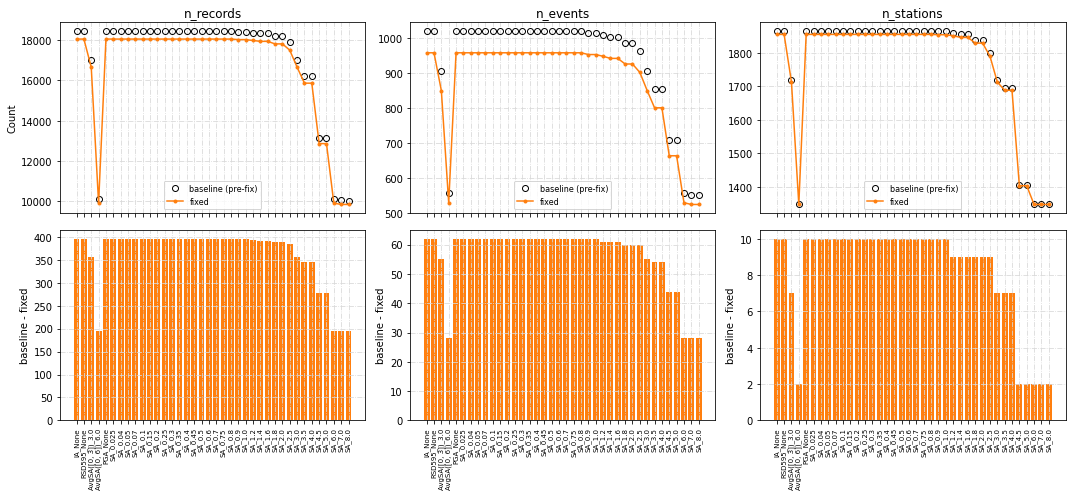

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
x = np.arange(len(sum_base))
for j, n_type in enumerate(["n_records", "n_events", "n_stations"]):
    ax = axs[0, j]
    ax.plot(x, sum_base[n_type], "o", mfc="none", c="k", label="baseline (pre-fix)")
    ax.plot(x, sum_fixed[n_type], ".-", c="tab:orange", label="fixed")
    ax.set_title(n_type)
    ax.grid(True, ls="-.", color="0.85")
    ax.legend(fontsize=8)
    ax = axs[1, j]
    ax.bar(x, sum_base[n_type] - sum_fixed[n_type], color="tab:orange")
    ax.set_ylabel("baseline - fixed")
    ax.grid(True, ls="-.", color="0.85")
    ax.set_xticks(x)
    ax.set_xticklabels([k.split("_", 1)[1] for k in sum_base.index], rotation=90, fontsize=7)
axs[0, 0].set_ylabel("Count")
plt.tight_layout()
savefig(fig, "02_record_counts_per_im.png")
plt.show()

## 3. Unchanged regions

The fix only changes which records go into the ASC flatfile. The `sslab`, `sinter` and `vran`
outputs (flatfiles, residuals, lmer summaries and correlations) must therefore be identical to
the baseline. The table counts the status of every output file per region, fault type and
status; `identical` means byte-identical.

In [7]:
file_cmp = pd.DataFrame([vars(r) for r in cmp.compare_roots(BASELINE, "live")])
file_cmp["fault type"] = file_cmp["path"].str.extract(r"(normal|reverse|strikeslip)")[0]
file_cmp["trt"] = file_cmp["path"].str.extract(r"/(asc|sslab|sinter|vran)_")[0]
status_table = (file_cmp.groupby(["trt", "fault type", "status"]).size()
                .unstack("status", fill_value=0))
display(status_table)
regional = file_cmp[file_cmp["trt"] != "asc"]
print("All sslab / sinter / vran outputs identical to the baseline:",
      bool((regional["status"] == "identical").all()))

status             different  identical
trt    fault type                      
asc    normal             14          0
       reverse            14          0
       strikeslip         14          0
sinter normal              0         14
       reverse             0         14
       strikeslip          0         14
sslab  normal              0         14
       reverse             0         14
       strikeslip          0         14
vran   normal              0         14
       reverse             0         14
       strikeslip          0         14

All sslab / sinter / vran outputs identical to the baseline: True


## 4. Variance components

The intercept (mean residual) and the standard deviations of the between-event (`tau`),
site-to-site (`phi_S2S`) and within-event single-station (`phi_ss`) residuals, and the total
`sigma`, against period for SA, before and after the fix. The bottom row shows fixed minus
baseline. The ASC outputs are the same for the three fault types (section 6), so `reverse` is
shown. The non-SA IMs are listed in the table below the figure.

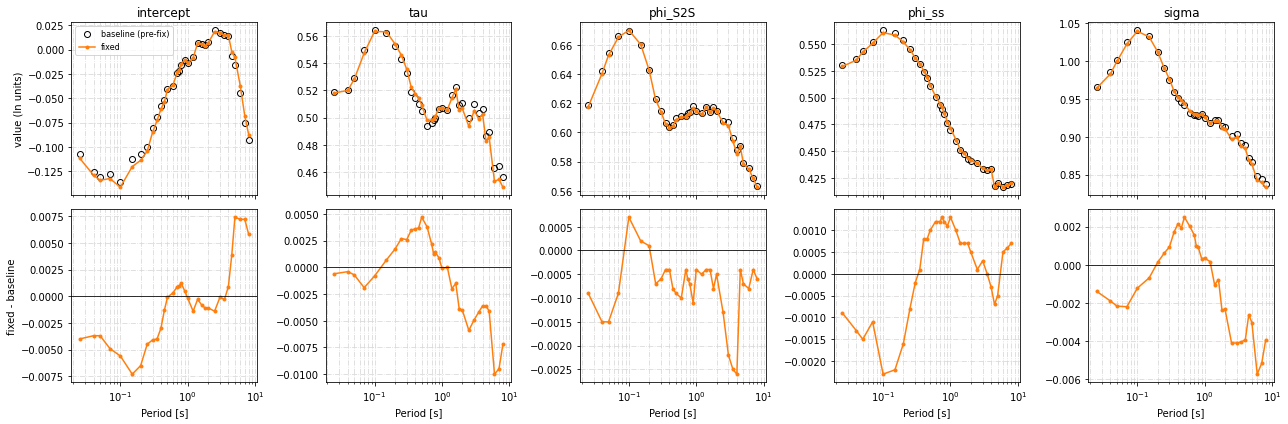

baseline                                     fixed                                 fixed - baseline                                
                         intercept     tau phi_S2S  phi_ss   sigma intercept     tau phi_S2S  phi_ss   sigma        intercept     tau phi_S2S  phi_ss   sigma
GM_IA_None                 -1.9980  1.0054  1.2512  0.9442  1.8622   -1.9850  1.0001  1.2504  0.9440  1.8587           0.0130 -0.0053 -0.0008 -0.0002 -0.0035
GM_RSD595_None              0.1695  0.2395  0.3603  0.3785  0.5748    0.1685  0.2362  0.3590  0.3792  0.5731          -0.0010 -0.0033 -0.0013  0.0007 -0.0017
rotD50_AvgSA([0, 3])_3.0   -0.0187  0.4568  0.5657  0.4010  0.8304   -0.0184  0.4555  0.5639  0.4015  0.8287           0.0003 -0.0013 -0.0018  0.0005 -0.0017
rotD50_AvgSA([0, 6])_6.0    0.0434  0.4212  0.5687  0.3711  0.7991    0.0453  0.4161  0.5681  0.3714  0.7961           0.0019 -0.0051 -0.0006  0.0003 -0.0030
rotD50_PGA_None            -0.1051  0.5205  0.6118  0.5282  0.9614   -0.1097  0.5200  0.6111  0.5276  0.9603          -0.0046 -0.0005 -0.0007 -0.0006 -0.0010

Largest |change| over all IMs:


,max |fixed - baseline|,at IM
intercept,0.013000,GM_IA_None
tau,0.010000,rotD50_SA_6.0
phi_S2S,0.002600,rotD50_SA_4.0
phi_ss,0.002300,rotD50_SA_0.1
sigma,0.005721,rotD50_SA_6.0


In [8]:
components = ["intercept", "tau", "phi_S2S", "phi_ss", "sigma"]
keys = list(sum_base.index)
is_sa = [parse_im_key(k)[1] == "SA" for k in keys]
T = np.array([parse_im_key(k)[2] for k, s in zip(keys, is_sa) if s])
b_sa, f_sa = sum_base.loc[is_sa], sum_fixed.loc[is_sa]

fig, axs = plt.subplots(2, 5, figsize=(18, 6), sharex=True)
for j, c in enumerate(components):
    ax = axs[0, j]
    ax.semilogx(T, b_sa[c], "o", mfc="none", c="k", label="baseline (pre-fix)")
    ax.semilogx(T, f_sa[c], ".-", c="tab:orange", label="fixed")
    ax.set_title(c)
    ax.grid(True, which="both", ls="-.", color="0.85")
    ax = axs[1, j]
    ax.semilogx(T, f_sa[c].to_numpy() - b_sa[c].to_numpy(), ".-", c="tab:orange")
    ax.axhline(0, c="k", lw=0.8)
    ax.set_xlabel("Period [s]")
    ax.grid(True, which="both", ls="-.", color="0.85")
axs[0, 0].legend(fontsize=8)
axs[0, 0].set_ylabel("value (ln units)")
axs[1, 0].set_ylabel("fixed - baseline")
plt.tight_layout()
savefig(fig, "04_variance_components.png")
plt.show()

non_sa = [k for k, s in zip(keys, is_sa) if not s]
vc_table = pd.concat({"baseline": sum_base.loc[non_sa, components],
                      "fixed": sum_fixed.loc[non_sa, components],
                      "fixed - baseline": sum_fixed.loc[non_sa, components]
                      - sum_base.loc[non_sa, components]}, axis=1)
display(vc_table.round(4))
d_all = (sum_fixed[components] - sum_base[components]).abs()
print("Largest |change| over all IMs:")
display(pd.DataFrame({"max |fixed - baseline|": d_all.max(), "at IM": d_all.idxmax()}))

## 5. Correlations

For each residual type, raw (`correlations/*.csv`) and positive-definite (`*_PD.csv`), and each
fault type, over the off-diagonal IM pairs:

- **max |Δρ|**, Δρ = ρ(fixed) − ρ(baseline), and the IM pair where it occurs;
- **max relative |Δρ| / |ρ|**, over pairs with **|ρ(baseline)| ≥ 0.1 only**: near ρ = 0 a
  relative difference is meaningless;
- **max Δρ in units of the sampling standard error.** On Fisher's z scale,
  $z = \tanh^{-1}\rho$, the sampling standard error of an estimated correlation is approximately
  $1/\sqrt{n-3}$ whatever the value of ρ, so

  $$\Delta_{SE} = \left| z_{\text{fixed}} - z_{\text{baseline}} \right| \sqrt{n - 3}$$

  is the change measured in standard errors. $n$ is the number of independent units the
  correlation is estimated from, taken from the **fixed** lmer summaries, per pair the smaller
  of the two IMs' counts:

  | residual type | $n$ |
  |---|---|
  | `rho_total`, `rho_total_B`, `rho_dWSes` | records (`n_records`) |
  | `rho_dBe` | events (`n_events`) |
  | `rho_dS2Ss` | stations (`n_stations`) |

In [9]:
N_TYPE = {"rho_total": "n_records", "rho_total_B": "n_records", "rho_dWSes": "n_records",
          "rho_dBe": "n_events", "rho_dS2Ss": "n_stations"}
REL_THRESHOLD = 0.1   # relative differences only where |rho_baseline| >= this


def rho_path(proc: Path, res: Path, ft: str, tag: str, kind: str) -> Path:
    if kind == "raw":
        return proc / ft / "correlations" / f"asc_{ft}_{tag}.csv"
    return res / ft / f"asc_{tag}_PD.csv"


def short(label: tuple) -> str:
    comp, im, p = label
    return im if p == "None" or im.startswith("AvgSA") else f"{im}({p:g})"


def rho_stats(ft: str, tag: str, kind: str) -> tuple[dict, pd.DataFrame, pd.DataFrame]:
    rb = read_correlation_csv(rho_path(BASE_PROC, BASE_RES, ft, tag, kind))
    rf = read_correlation_csv(rho_path(FIXED_PROC, FIXED_RES, ft, tag, kind))
    assert rb.index.equals(rf.index) and rb.columns.equals(rf.columns)
    labels = list(rb.index)

    # n per IM from the fixed summaries, then per pair the smaller of the two
    s = load_summary(FIXED_PROC, ft, "asc")
    n_by_label = {parse_im_key(k): s.at[k, N_TYPE[tag]] for k in s.index}
    n_im = np.array([n_by_label[lab] for lab in labels])
    n_pair = np.minimum.outer(n_im, n_im)

    b, f = rb.to_numpy(float), rf.to_numpy(float)
    iu = np.triu_indices_from(b, k=1)            # off-diagonal pairs, each once
    d = f - b
    absd = np.abs(d[iu])
    i_max = int(np.argmax(absd))

    big = np.abs(b[iu]) >= REL_THRESHOLD
    rel = np.where(big, absd / np.abs(b[iu]), np.nan)
    i_rel = int(np.nanargmax(rel))

    clip = 1 - 1e-12                             # keep arctanh finite
    z_se = (np.abs(np.arctanh(np.clip(f[iu], -clip, clip)) - np.arctanh(np.clip(b[iu], -clip, clip)))
            * np.sqrt(n_pair[iu] - 3))
    i_se = int(np.argmax(z_se))

    def pair(k: int) -> str:
        return f"{short(labels[iu[0][k]])} - {short(labels[iu[1][k]])}"

    stats = {"fault type": ft, "residual type": tag, "matrix": kind,
             "max |dRho|": absd[i_max], "pair (max |dRho|)": pair(i_max),
             "max rel |dRho|/|rho|": rel[i_rel], "pair (max rel)": pair(i_rel),
             "max dRho [SE units]": z_se[i_se], "pair (max SE)": pair(i_se),
             "n used": N_TYPE[tag], "n range": f"{int(n_im.min())}-{int(n_im.max())}"}
    return stats, rb, rf


stats_rows, mats = [], {}
for ft in FAULT_TYPES:
    for tag in RHO_TAGS:
        for kind in ["raw", "PD"]:
            st, rb, rf = rho_stats(ft, tag, kind)
            stats_rows.append(st)
            mats[(ft, tag, kind)] = (rb, rf)
rho_table = pd.DataFrame(stats_rows)
display(rho_table.round(4))

,fault type,residual type,matrix,max |dRho|,pair (max |dRho|),max rel |dRho|/|rho|,pair (max rel),max dRho [SE units],pair (max SE),n used,n range
0,normal,rho_total,raw,0.0133,RSD595 - SA(5),0.0396,"RSD595 - AvgSA([0, 3])",1.9123,SA(4) - SA(4.5),n_records,9850-18045
1,normal,rho_total,PD,0.0133,RSD595 - SA(5),0.0396,"RSD595 - AvgSA([0, 3])",1.9123,SA(4) - SA(4.5),n_records,9850-18045
2,normal,rho_total_B,raw,0.0157,RSD595 - SA(5),0.0428,"RSD595 - AvgSA([0, 3])",1.8105,IA - SA(5),n_records,9850-18045
3,normal,rho_total_B,PD,0.0157,RSD595 - SA(5),0.0428,"RSD595 - AvgSA([0, 3])",1.8084,IA - SA(5),n_records,9850-18045
4,normal,rho_dBe,raw,0.0172,SA(0.1) - SA(6),0.0380,SA(0.1) - SA(6),1.1924,SA(0.05) - SA(0.07),n_events,524-957
5,normal,rho_dBe,PD,0.0173,SA(0.1) - SA(6),0.0381,SA(0.1) - SA(6),1.8181,SA(0.05) - SA(0.07),n_events,524-957
6,normal,rho_dS2Ss,raw,0.0314,RSD595 - SA(5),0.1374,RSD595 - SA(5),1.2500,RSD595 - SA(5),n_stations,1347-1855
7,normal,rho_dS2Ss,PD,0.0314,RSD595 - SA(5),0.1374,RSD595 - SA(5),1.2500,RSD595 - SA(5),n_stations,1347-1855
8,normal,rho_dWSes,raw,0.0099,IA - SA(0.15),0.0277,RSD595 - SA(5),3.0578,IA - SA(0.15),n_records,9850-18045
9,normal,rho_dWSes,PD,0.0099,IA - SA(0.15),0.0277,RSD595 - SA(5),3.0578,IA - SA(0.15),n_records,9850-18045


### Δρ heatmaps (reverse, positive-definite matrices)

Each cell is ρ(fixed) − ρ(baseline) for one IM pair. The colour scale is symmetric and shared by
the five panels, so the residual types can be compared directly.

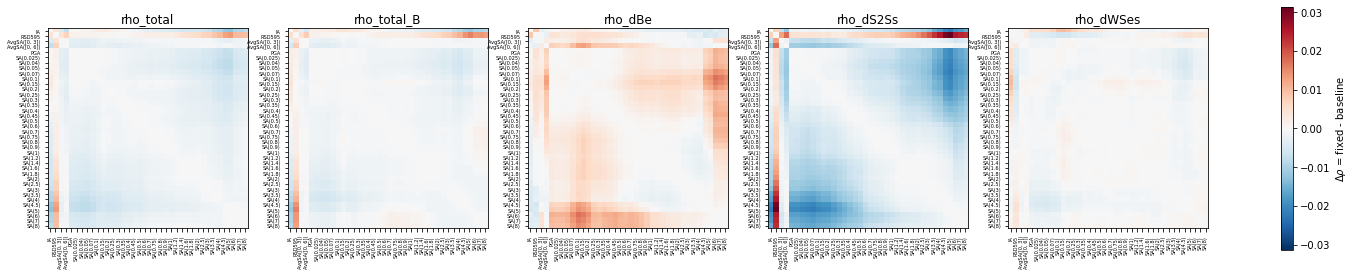

In [10]:
fig, axs = plt.subplots(1, 5, figsize=(26, 5.6))
vmax = max(np.abs((mats[("reverse", t, "PD")][1] - mats[("reverse", t, "PD")][0]).to_numpy()).max()
           for t in RHO_TAGS)
for ax, tag in zip(axs, RHO_TAGS):
    rb, rf = mats[("reverse", tag, "PD")]
    im = ax.imshow((rf - rb).to_numpy(), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    lab = [short(l) for l in rb.index]
    ax.set_xticks(range(len(lab)))
    ax.set_xticklabels(lab, rotation=90, fontsize=5)
    ax.set_yticks(range(len(lab)))
    ax.set_yticklabels(lab, fontsize=5)
    ax.set_title(tag)
fig.colorbar(im, ax=axs, shrink=0.8, label=r"$\Delta\rho$ = fixed - baseline")
savefig(fig, "05a_delta_rho_heatmaps_reverse_PD.png")
plt.show()

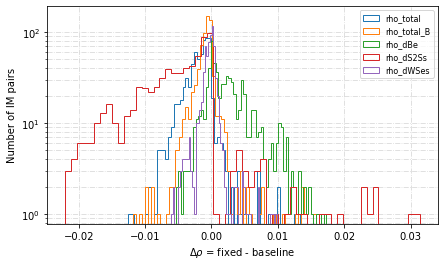

In [11]:
# distribution of all off-diagonal changes, per residual type (reverse, PD)
fig, ax = plt.subplots(figsize=(7, 4))
for tag in RHO_TAGS:
    rb, rf = mats[("reverse", tag, "PD")]
    d = (rf - rb).to_numpy()[np.triu_indices(len(rb), k=1)]
    ax.hist(d, bins=60, histtype="step", lw=1.3, label=tag)
ax.set_xlabel(r"$\Delta\rho$ = fixed - baseline")
ax.set_ylabel("Number of IM pairs")
ax.set_yscale("log")
ax.grid(True, which="both", ls="-.", color="0.85")
ax.legend(fontsize=8)
savefig(fig, "05b_delta_rho_histogram_reverse_PD.png")
plt.show()

### ρ against period for the pairs used downstream

The correlations that feed record selection and the conditional spectra: `AvgSA([0, 3])` with
every SA; SA(T) with `RSD595`; and SA(T₁) with SA(T) for T₁ = 0.1, 0.5, 1 and 2 s. Positive-
definite matrices, reverse; open circles are the baseline, lines the fixed run. The scalar pairs
`AvgSA([0, 3])`–`RSD595` and `AvgSA([0, 3])`–`IA` are in the table after the figures.

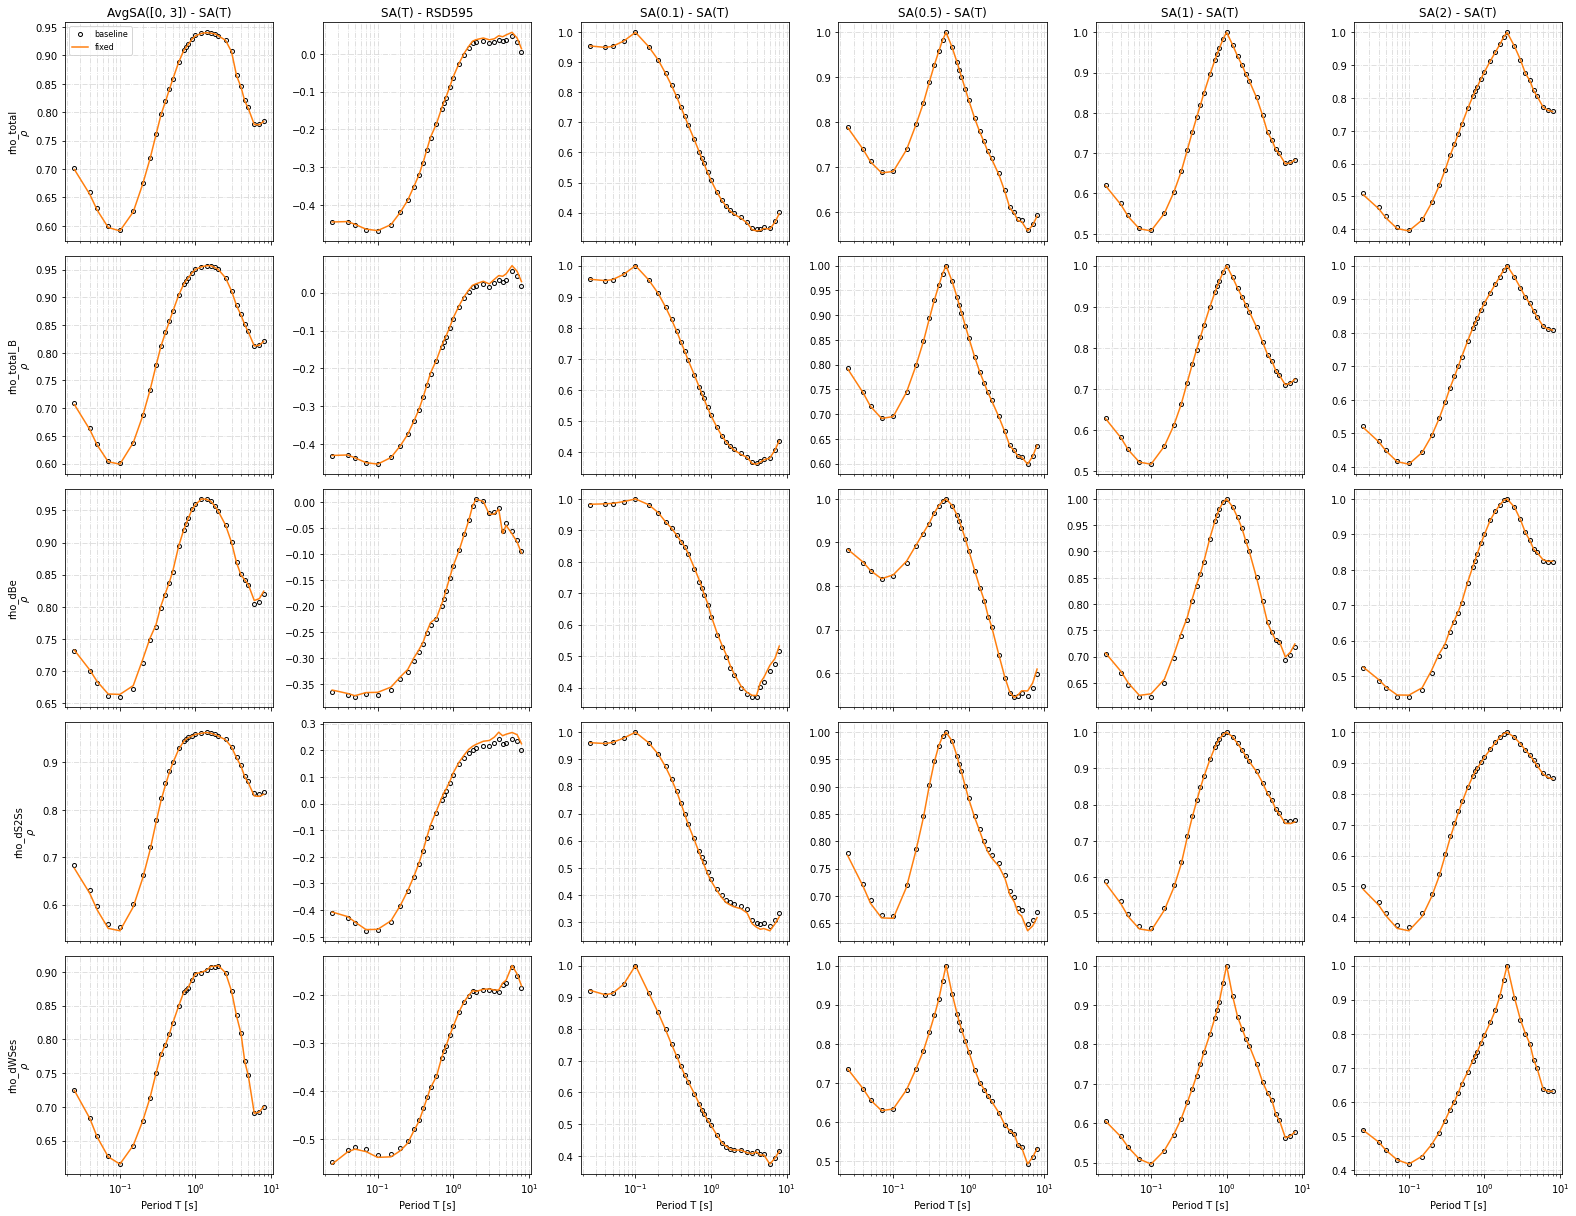

,residual type,pair,baseline,fixed,fixed - baseline
0,rho_total,"AvgSA([0, 3]) - RSD595",-0.1072,-0.1030,0.0042
1,rho_total,"AvgSA([0, 3]) - IA",0.6804,0.6762,-0.0043
2,rho_total_B,"AvgSA([0, 3]) - RSD595",-0.1034,-0.0990,0.0044
3,rho_total_B,"AvgSA([0, 3]) - IA",0.6908,0.6882,-0.0026
4,rho_dBe,"AvgSA([0, 3]) - RSD595",-0.1386,-0.1389,-0.0004
5,rho_dBe,"AvgSA([0, 3]) - IA",0.6091,0.6063,-0.0027
6,rho_dS2Ss,"AvgSA([0, 3]) - RSD595",0.0616,0.0742,0.0126
7,rho_dS2Ss,"AvgSA([0, 3]) - IA",0.7199,0.7126,-0.0073
8,rho_dWSes,"AvgSA([0, 3]) - RSD595",-0.3405,-0.3408,-0.0003
9,rho_dWSes,"AvgSA([0, 3]) - IA",0.6690,0.6705,0.0015


In [12]:
def sa_row(rho: pd.DataFrame, label: tuple) -> tuple[np.ndarray, np.ndarray]:
    # the correlations of `label` with every SA, against SA period
    cols = [c for c in rho.columns if c[1] == "SA"]
    return np.array([c[2] for c in cols]), rho.loc[[label], cols].to_numpy().ravel()


avg03 = next(l for l in mats[("reverse", "rho_total", "PD")][0].index if l[1] == "AvgSA([0, 3])")
rsd = next(l for l in mats[("reverse", "rho_total", "PD")][0].index if l[1] == "RSD595")
ia = next(l for l in mats[("reverse", "rho_total", "PD")][0].index if l[1] == "IA")
T1S = [0.1, 0.5, 1.0, 2.0]

panels = [("AvgSA([0, 3]) - SA(T)", [avg03]), ("SA(T) - RSD595", [rsd])] + \
         [(f"SA({t1:g}) - SA(T)", [("rotD50", "SA", t1)]) for t1 in T1S]

fig, axs = plt.subplots(len(RHO_TAGS), len(panels), figsize=(22, 17), sharex=True)
for i, tag in enumerate(RHO_TAGS):
    rb, rf = mats[("reverse", tag, "PD")]
    for j, (title, (lab,)) in enumerate(panels):
        ax = axs[i, j]
        Tb, yb = sa_row(rb, lab)
        Tf, yf = sa_row(rf, lab)
        ax.semilogx(Tb, yb, "o", mfc="none", ms=4, c="k", label="baseline")
        ax.semilogx(Tf, yf, "-", c="tab:orange", label="fixed")
        ax.grid(True, which="both", ls="-.", color="0.85")
        if i == 0:
            ax.set_title(title)
        if j == 0:
            ax.set_ylabel(f"{tag}\n" + r"$\rho$")
        if i == len(RHO_TAGS) - 1:
            ax.set_xlabel("Period T [s]")
axs[0, 0].legend(fontsize=8)
plt.tight_layout()
savefig(fig, "05c_rho_vs_period_downstream_pairs_reverse_PD.png")
plt.show()

scalar_rows = []
for tag in RHO_TAGS:
    rb, rf = mats[("reverse", tag, "PD")]
    for other in (rsd, ia):
        scalar_rows.append({"residual type": tag, "pair": f"AvgSA([0, 3]) - {other[1]}",
                            "baseline": rb.loc[[avg03], [other]].iat[0, 0],
                            "fixed": rf.loc[[avg03], [other]].iat[0, 0]})
scalar = pd.DataFrame(scalar_rows)
scalar["fixed - baseline"] = scalar["fixed"] - scalar["baseline"]
display(scalar.round(4))

## 6. Rake issue (reported, not fixed)

nb 002 cell 13 builds the ASC flatfile from `esm_df`, not from `df`, the copy whose rake is reset
per fault type by `mf.set_new_rake`. If so, the ASC outputs are the same for the three fault
types: every ASC flatfile uses the rake = 90 assumption of cell 10. Separately, `set_new_rake`
updates `rake` but not `fault_dip`, `rup_width` or `ztor`, which `add_site_rup_ctx_columns`
derived from rake = 90. Both are checked on the fixed outputs below. Neither is changed by the
filter fix.

In [13]:
ident = rake.outputs_identical_across_fault_types("live")
display(ident.pivot(index="output", columns="trt", values="identical for all 3 fault types"))
print("Rake and rake-derived geometry, compared between fault types (fixed flatfiles):")
display(rake.rake_columns_by_fault_type("live"))

trt,asc,sinter,sslab,vran
output,,,,
flatfile,True,False,False,False
partitioned residuals,True,True,False,False
rho_dBe (PD),True,True,False,False
rho_dBe (raw),True,True,False,False
rho_dS2Ss (PD),True,True,False,False
rho_dS2Ss (raw),True,True,False,False
rho_dWSes (PD),True,True,False,False
rho_dWSes (raw),True,True,False,False
rho_total (PD),True,True,False,False


Rake and rake-derived geometry, compared between fault types (fixed flatfiles):


,trt,comparison,rows,rows where rake differs,rows where fault_dip differs,rows where rup_width differs,rows where ztor differs
0,asc,reverse vs normal,18075,0,0,0,0
1,asc,reverse vs strikeslip,18075,0,0,0,0
2,sslab,reverse vs normal,624,67,0,0,0
3,sslab,reverse vs strikeslip,624,67,0,0,0
4,sinter,reverse vs normal,546,252,0,0,0
5,sinter,reverse vs strikeslip,546,252,0,0,0
6,vran,reverse vs normal,649,114,0,0,0
7,vran,reverse vs strikeslip,649,114,0,0,0


## 7. Summary

Per residual type, the largest change over the raw and positive-definite matrices and all three
fault types: max |Δρ|, max relative change (pairs with |ρ(baseline)| ≥ 0.1) and max change in
sampling standard errors. The verdict follows the criterion stated at the top: **the change is
immaterial if every |Δρ| is well below one sampling standard error.** "Well below" is read here
as at most half a standard error; between 0.5 and 1 SE is reported as borderline, and 1 SE or
more fails.

In [14]:
summary = rho_table.groupby("residual type").agg(
    **{"max |dRho|": ("max |dRho|", "max"),
       "max rel |dRho|/|rho| (|rho|>=0.1)": ("max rel |dRho|/|rho|", "max"),
       "max dRho [SE units]": ("max dRho [SE units]", "max"),
       "n used": ("n used", "first")}).reindex(RHO_TAGS)
# the pair behind each SE maximum
where = rho_table.loc[rho_table.groupby("residual type")["max dRho [SE units]"].idxmax()]
summary["pair (max SE)"] = where.set_index("residual type")["pair (max SE)"].reindex(RHO_TAGS)
display(summary.round(4))

worst = summary["max dRho [SE units]"].max()
worst_tag = summary["max dRho [SE units]"].idxmax()
verdict = ("MET: every |dRho| is well below one sampling standard error" if worst <= 0.5 else
           "BORDERLINE: every |dRho| is below one standard error, but not well below" if worst < 1
           else "NOT MET: at least one |dRho| is one sampling standard error or more")
print(f"Largest change: {worst:.3f} standard errors ({worst_tag}, "
      f"{summary.at[worst_tag, 'pair (max SE)']}).")
print(f"Largest |dRho|: {summary['max |dRho|'].max():.4f}.")
print(f"Criterion: {verdict}.")

,max |dRho|,max rel |dRho|/|rho| (|rho|>=0.1),max dRho [SE units],n used,pair (max SE)
residual type,,,,,
rho_total,0.0133,0.0396,1.9123,n_records,SA(4) - SA(4.5)
rho_total_B,0.0157,0.0428,1.8105,n_records,IA - SA(5)
rho_dBe,0.0173,0.0381,1.8181,n_events,SA(0.05) - SA(0.07)
rho_dS2Ss,0.0314,0.1374,1.2500,n_stations,RSD595 - SA(5)
rho_dWSes,0.0099,0.0277,3.0578,n_records,IA - SA(0.15)


Largest change: 3.058 standard errors (rho_dWSes, IA - SA(0.15)).
Largest |dRho|: 0.0314.
Criterion: NOT MET: at least one |dRho| is one sampling standard error or more.


### How widespread are the changes?

The maximum is one pair. The table counts, per residual type (reverse, PD), how many of the
off-diagonal IM pairs change by at least 0.5 and at least 1 sampling standard error, and shows
ρ and Δρ at the pair with the largest change in SE units. On Fisher's z scale a given Δρ counts
for more SEs the closer |ρ| is to 1, so a pair of neighbouring periods with ρ ≈ 0.99 can exceed
1 SE with a very small Δρ. That is part of the criterion, not a reason to set it aside; the
table only shows where the exceedances are.

In [15]:
rows = []
for tag in RHO_TAGS:
    rb, rf = mats[("reverse", tag, "PD")]
    labels = list(rb.index)
    s = load_summary(FIXED_PROC, "reverse", "asc")
    n_by_label = {parse_im_key(k): s.at[k, N_TYPE[tag]] for k in s.index}
    n_im = np.array([n_by_label[l] for l in labels])
    iu = np.triu_indices(len(labels), k=1)
    b, f = rb.to_numpy(float)[iu], rf.to_numpy(float)[iu]
    clip = 1 - 1e-12
    se = (np.abs(np.arctanh(np.clip(f, -clip, clip)) - np.arctanh(np.clip(b, -clip, clip)))
          * np.sqrt(np.minimum.outer(n_im, n_im)[iu] - 3))
    k = int(np.argmax(se))
    rows.append({"residual type": tag, "IM pairs": len(se),
                 "pairs >= 0.5 SE": int((se >= 0.5).sum()),
                 "pairs >= 1 SE": int((se >= 1).sum()),
                 "% pairs >= 1 SE": 100 * (se >= 1).mean(),
                 "worst pair": f"{short(labels[iu[0][k]])} - {short(labels[iu[1][k]])}",
                 "rho baseline": b[k], "rho fixed": f[k], "dRho": f[k] - b[k],
                 "SE units": se[k]})
spread = pd.DataFrame(rows).set_index("residual type")
display(spread.round(4))

,IM pairs,pairs >= 0.5 SE,pairs >= 1 SE,% pairs >= 1 SE,worst pair,rho baseline,rho fixed,dRho,SE units
residual type,,,,,,,,,
rho_total,703,411,36,5.1209,SA(4) - SA(4.5),0.9745,0.9737,-0.0009,1.9123
rho_total_B,703,155,22,3.1294,IA - SA(5),0.5125,0.5006,-0.0119,1.8084
rho_dBe,703,16,2,0.2845,SA(0.05) - SA(0.07),0.9957,0.9962,0.0005,1.8181
rho_dS2Ss,703,311,5,0.7112,RSD595 - SA(5),0.2285,0.2599,0.0314,1.2500
rho_dWSes,703,62,14,1.9915,IA - SA(0.15),0.7470,0.7569,0.0099,3.0578


### Conclusion

The verdict printed above is computed from the numbers, so it is the conclusion of this notebook
whatever the data: the criterion is met only if every Δρ, over all residual types, raw and PD
matrices and fault types, is at most half a sampling standard error. The absolute changes
(max |Δρ|) and the spread table show how large the changes are in ρ itself and how many pairs
exceed the criterion. Whether a change of that size in ρ matters for the downstream record
selection is a separate judgement; the criterion set for this check is the SE one.

Based on the plots of the correlation coefficients I am satisfied that the difference is not significant enough to warrant new record selections in my subsequent work however and update to correlations in openquake is required and the paper should report the newest versions. By citing OpenQuake v3.26.0 as the version used to do the record selection I am ok.